# Example Notebook LSTM ISRFs

Step 1: load the tabulated ISRFs and plot them.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
#Importing general libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

In [3]:
#Importing specific lstm functions
from lstm_perf.isrf import read_isrf

## Load the ISRFs

In [4]:
# Each entry is a channel: (wavelength in µm, response in µm-1, normalised to integrate to 1)
isrf = read_isrf("isrf_norm.csv")
list(isrf)

['VNIR0',
 'VNIR1',
 'VNIR2',
 'VNIR3a',
 'VNIR3b',
 'SWIR1',
 'SWIR2',
 'TIR1',
 'TIR2',
 'TIR3',
 'TIR4',
 'TIR5']

In [5]:
# We check the normalisation and the wavelength range of each channel
for name, (wl, resp) in isrf.items():
    print(f"{name:7s} {wl[0]:7.3f}-{wl[-1]:7.3f} µm  {wl.size:6d} points  integral = {trapezoid(resp, wl):.6f}")

VNIR0     0.300-  1.000 µm    1400 points  integral = 1.000000
VNIR1     0.300-  1.000 µm    1400 points  integral = 1.000000
VNIR2     0.300-  1.000 µm    1400 points  integral = 1.000000
VNIR3a    0.750-  2.650 µm    3800 points  integral = 1.000000
VNIR3b    0.750-  2.650 µm    3800 points  integral = 1.000000
SWIR1     0.750-  2.650 µm    3800 points  integral = 1.000000
SWIR2     0.750-  2.650 µm    3800 points  integral = 1.000000
TIR1      2.000- 13.999 µm   23999 points  integral = 1.000000
TIR2      2.000- 13.999 µm   23999 points  integral = 1.000000
TIR3      2.000- 13.999 µm   23999 points  integral = 1.000000
TIR4      2.000- 13.999 µm   23999 points  integral = 1.000000
TIR5      2.000- 13.999 µm   23999 points  integral = 1.000000


In [6]:
# The TIR channels only
tir = {name: ch for name, ch in isrf.items() if name.startswith("TIR")}
list(tir)

['TIR1', 'TIR2', 'TIR3', 'TIR4', 'TIR5']

## Plot the ISRFs

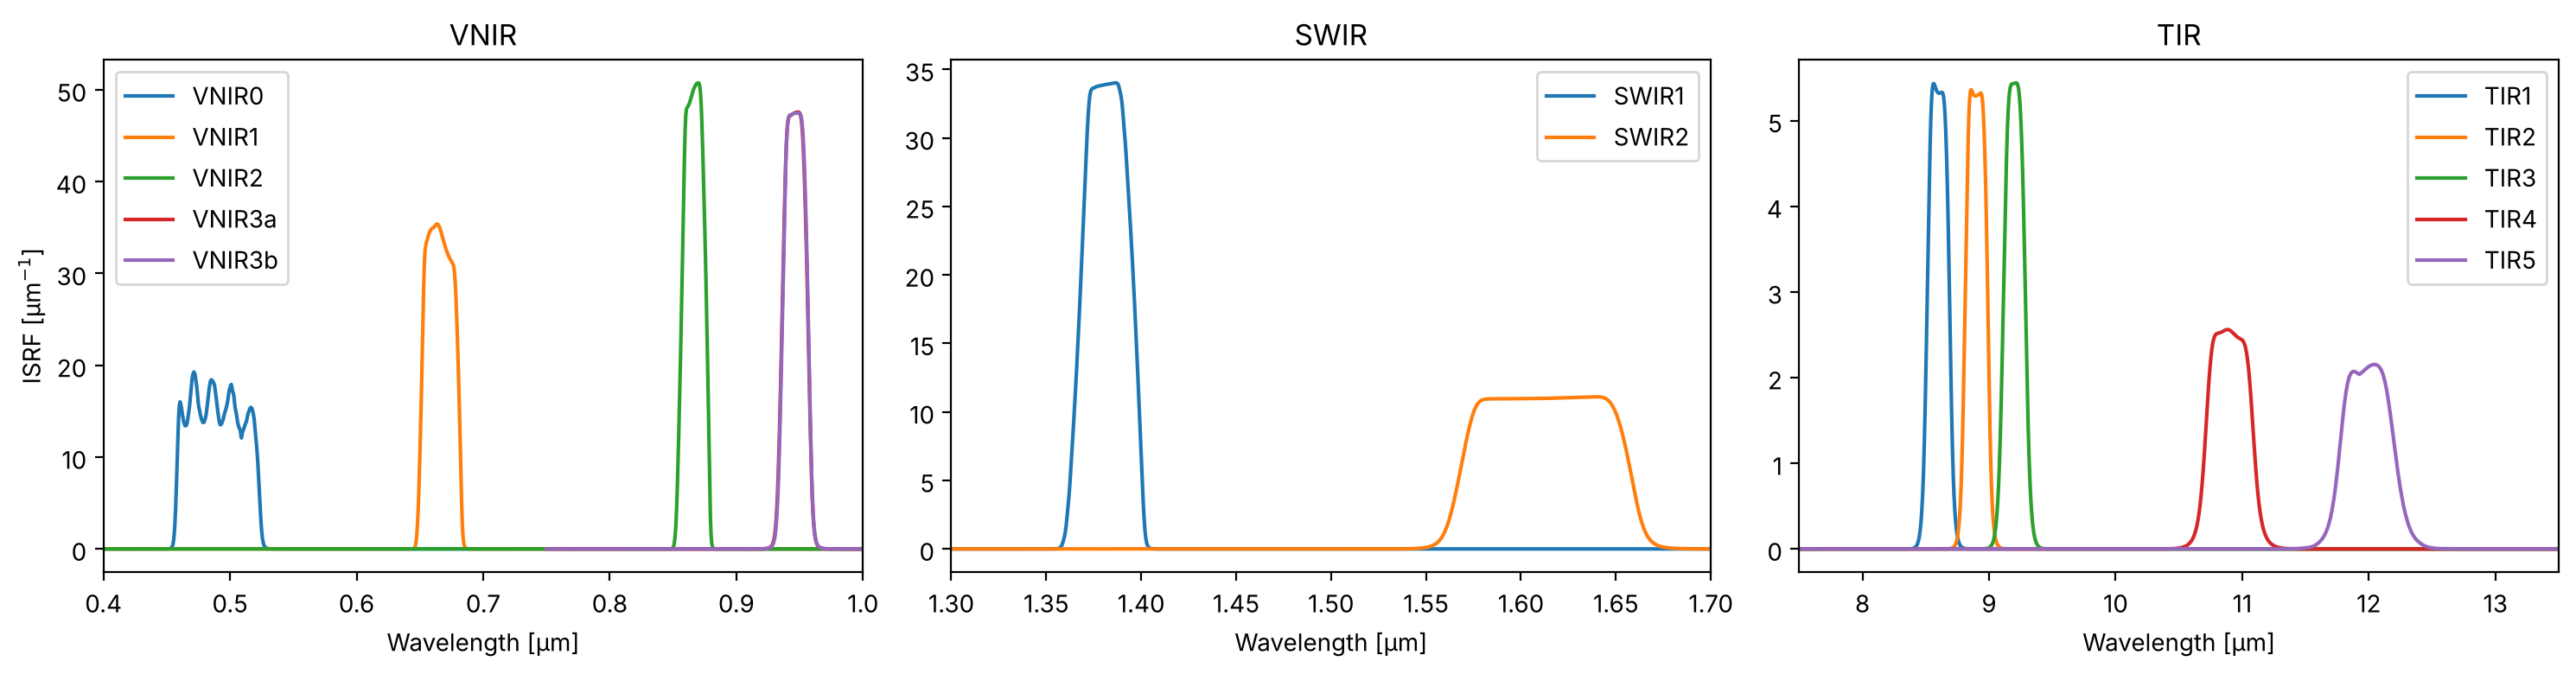

In [7]:
# One panel per spectral range
groups = {"VNIR": (0.4, 1.0), "SWIR": (1.3, 1.7), "TIR": (7.5, 13.5)}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (prefix, xlim) in zip(axes, groups.items()):
    for name, (wl, resp) in isrf.items():
        if name.startswith(prefix):
            ax.plot(wl, resp, label=name)
    ax.set_xlim(xlim)
    ax.set_title(prefix)
    ax.set_xlabel("Wavelength [µm]")
    ax.legend()
axes[0].set_ylabel(r"ISRF [µm$^{-1}$]")
plt.tight_layout()

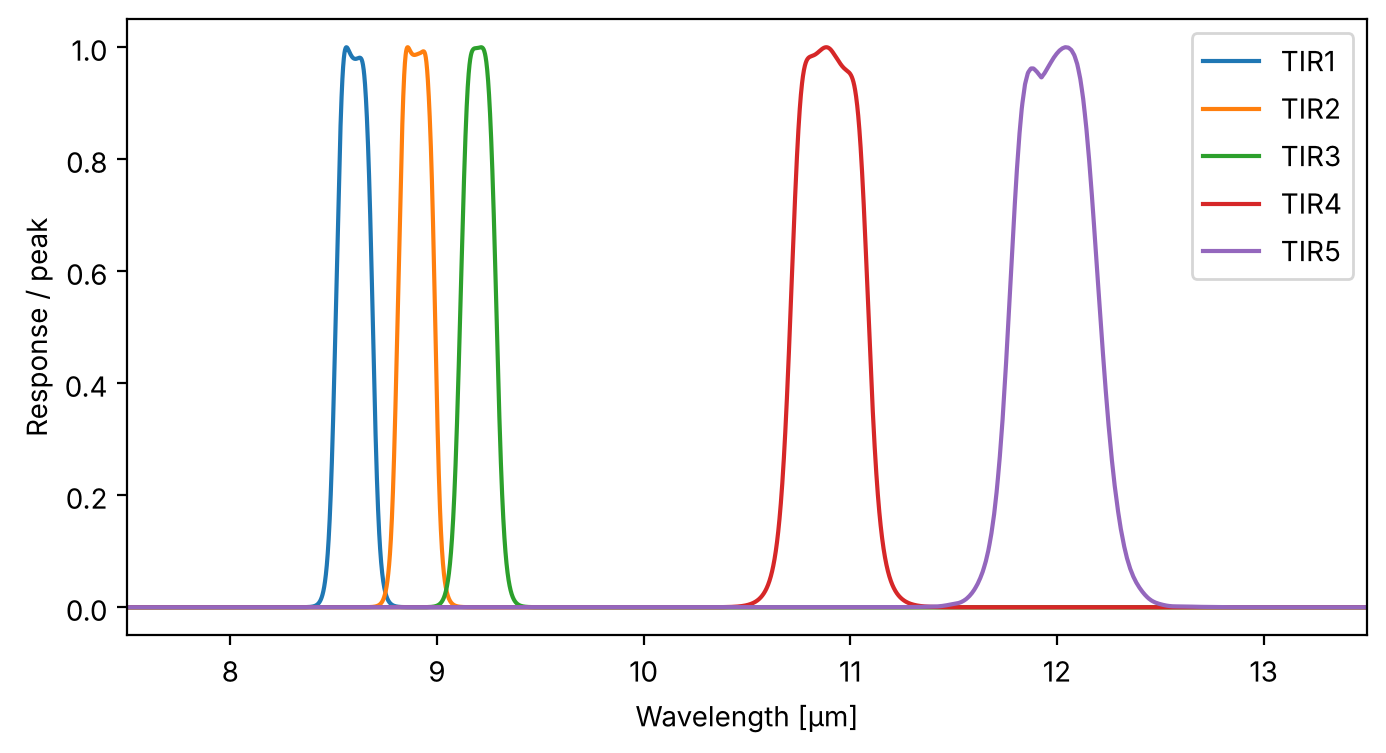

In [8]:
# The TIR channels, peak-normalised so their shapes compare directly
fig, ax = plt.subplots(figsize=(8, 4))
for name, (wl, resp) in tir.items():
    ax.plot(wl, resp / resp.max(), label=name)
ax.set_xlim(7.5, 13.5)
ax.set_xlabel("Wavelength [µm]")
ax.set_ylabel("Response / peak")
ax.legend()